# Independent kidney cohort: fragment-length removal ablation across depth (Supp. Fig. Y)

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Frozen, Cristiano-trained LEAF-1, DELFI and fragment-length models on the 12
independent kidney-cohort samples at 10,000-100,000 fragments, on the original
bags and on bags resampled so that every sample has one shared fragment-length
histogram: the label-free pooled target, or the cancer-reference target. Lines
are the mean ROC AUC over 10 with-replacement bags; shading is the paired
class-stratified hierarchical-bootstrap 95% CI (2,000 iterations). The
fragment-length model uses per-sample length percentiles, so it sits at 0.5 by
construction once lengths are matched.

The values are the LEAF-1, DELFI and fragment-length rows of the extended
length-matching summary that Fig. 6e also reads; they equal the source plot's
table (`supp_figY_length_ablation/cfdna_length_ablation_depth_plot_data.tsv`)
exactly. The source plot script is on the rrg-hsn cluster, so the panel is
redrawn here: same colours and line styles, "LEAF1" spelt LEAF-1, title and
subtitle moved to the legend, panel letters a-c, 180 mm wide (was 189 mm).

Panel:
- `cfdna_kidney_length_ablation_depth`

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Constants and data ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DEPTHS = [10000, 25000, 50000, 75000, 100000]
MODELS = [("leaf1", "LEAF-1"), ("delfi", "DELFI"), ("length", "Fragment length")]
# Variant colours as in Fig. 6e and the source figure.
VARIANTS = [("original", "Original bags (unmatched)", "#0072B2", "-", "o"),
            ("pooled", "Length-matched, pooled target", "#D55E00", (0, (4, 1.6)), "s"),
            ("cancer_reference", "Length-matched, cancer-reference target", "#009E73", ":", "^")]
PANEL_RC = {"font.size": 6, "axes.titlesize": 6.5, "axes.labelsize": 6.5,
            "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6}

s = pd.read_csv(DATA / "cfdna_kidney_length_matching_depth_summary.csv", float_precision="round_trip")
d = s[s.model.isin([m for m, _ in MODELS]) & s.variant.isin([v[0] for v in VARIANTS])].copy()
assert len(d) == len(MODELS) * len(VARIANTS) * len(DEPTHS) and (d.n_repeats == 10).all()
assert sorted(d.sample_size.unique()) == DEPTHS

saved: cfdna/output/cfdna_kidney_length_ablation_depth.pdf
saved: cfdna/output/cfdna_kidney_length_ablation_depth.png
saved: cfdna/output/cfdna_kidney_length_ablation_depth.svg
saved: cfdna/output/cfdna_kidney_length_ablation_depth.tsv


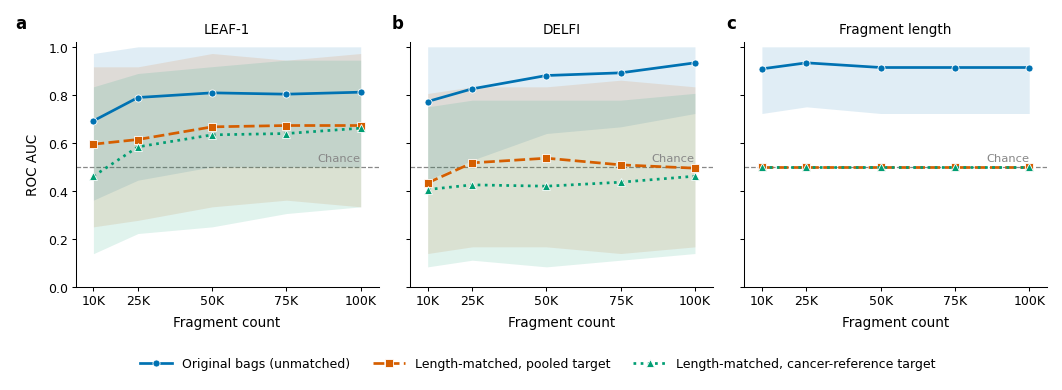

mean ROC AUC at 100K fragments:
variant  cancer_reference  original  pooled
model                                      
delfi               0.461     0.933   0.494
leaf1               0.661     0.811   0.672
length              0.500     0.914   0.500


In [3]:
# ── Figure ─────────────────────────────────────────────────────────────────────
with plt.rc_context(PANEL_RC):
    fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.55), sharey=True)
    for ax, (model, title), letter in zip(axes, MODELS, "abc"):
        for variant, label, color, ls, marker in VARIANTS:
            r = d[(d.model == model) & (d.variant == variant)].sort_values("sample_size")
            ax.fill_between(r.sample_size, r.ci95_low, r.ci95_high, color=color, alpha=0.12,
                            linewidth=0, zorder=1)
            ax.plot(r.sample_size, r.mean_roc_auc, color=color, ls=ls, marker=marker, lw=1.3,
                    ms=3.4, markeredgecolor="white", markeredgewidth=0.4, label=label, zorder=3)
        ax.axhline(0.5, color="#888888", ls="--", lw=0.6, zorder=0)
        ax.text(DEPTHS[-1], 0.515, "Chance", ha="right", va="bottom", fontsize=5.5, color="#888888")
        ax.set_xticks(DEPTHS); ax.set_xticklabels([f"{x // 1000}K" for x in DEPTHS])
        ax.set_xlim(DEPTHS[0] - 6000, DEPTHS[-1] + 6000)
        ax.set_ylim(0, 1.02); ax.set_yticks(np.arange(0, 1.01, 0.2))
        ax.set_xlabel("Fragment count"); ax.set_title(title, pad=4)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="both", length=2, pad=1.5, width=0.5)
        ax.text(-0.2 if letter == "a" else -0.06, 1.04, letter, transform=ax.transAxes,
                fontsize=8, fontweight="bold", va="bottom")
    axes[0].set_ylabel("ROC AUC")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.tight_layout(rect=(0, 0.1, 1, 1), w_pad=1.2)
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False,
               bbox_to_anchor=(0.5, 0.0), handlelength=2.6, columnspacing=1.8)
    out = d.sort_values(["model", "variant", "sample_size"]).reset_index(drop=True)
    savefig(fig, OUT, "cfdna_kidney_length_ablation_depth", data=out)
    plt.show()
at100 = d[d.sample_size == 100000].pivot(index="model", columns="variant", values="mean_roc_auc")
print("mean ROC AUC at 100K fragments:"); print(at100.round(3).to_string())